# Проверка четырёх моделей атрибуции

Цель: проверить расчёты и устойчивость рейтингов перед работой с реальными касаниями и будущим A/B-тестом. Это проверка функции платформы, не всего бота, доступа или хранения данных. Исторические покупки фиксированы; касания вымышлены. Причинного эталона нет, точность выбора действительно эффективной рекламы здесь не измеряется.

Используется настоящая `core.attribution.compute`, без записи в базу. Внутреннее объединение функции сохранено: новые объединения экспериментальных таблиц не добавляются. Категории и курс не влияют на веса. Затраты неизвестны — ROMI не рассчитывается. Нет предыстории до начала доступного периода.


In [1]:
from pathlib import Path
import sys, json, hashlib, io, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data/raw/base.csv').exists())
sys.path.insert(0, str(ROOT/'src'))
from core.attribution import compute
MODELS = ['first', 'last', 'linear', 'position']
BASE_SEED = 42
SEEDS = list(range(20))  # 20 повторов на каждое предположение
WINDOW_DAYS = 30
TOP_K = 3
CONFIGS = {
    'Базовое': {'probabilities': [.30,.35,.25,.10], 'delay': 7.},
    'Меньше касаний': {'probabilities': [.30,.55,.10,.05], 'delay': 7.},
    'Больше касаний': {'probabilities': [.30,.10,.25,.35], 'delay': 7.},
    'Ближе к покупке': {'probabilities': [.30,.35,.25,.10], 'delay': 2.},
    'Дальше от покупки': {'probabilities': [.30,.35,.25,.10], 'delay': 14.},
}
OUTPUT = ROOT/'outputs/experiments/attribution_validation'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})
def save(fig, name):
    fig.savefig(OUTPUT/(name+'.png'), dpi=145, bbox_inches='tight')
    fig.savefig(OUTPUT/(name+'.svg'), bbox_inches='tight')
    plt.show()


## 1. Ручные ответы и граничные случаи

Каждый пример выполняется для четырёх моделей. Ожидаемая выручка задана явно, независимо от формул проверяемой функции. Для денежных сумм сравнение допускает только численную погрешность float (0,000001 ₽), а не округление до рубля. Проверка двух курсов начинается с двух позиций разной стоимости и одного заказа.


In [2]:
T = pd.Timestamp('2026-09-01 12:00', tz='Europe/Moscow')
def order(oid='o', time=T, amount=100., user='u'):
    return dict(order_id=oid,user_id_hash=user,timestamp=time,amount=amount,variable_costs=0.)
def touch(i, days=1, placement=None, user='u', time=None):
    return dict(touch_id=i,user_id_hash=user,placement_id=placement or f'p{i}',timestamp=time if time is not None else T-pd.Timedelta(days=days))
def same(expected):return {m:expected for m in MODELS}
cases = [
 ('Одно касание',[touch(1)],[order()],same({'o':{'p1':100}})),
 ('Два касания',[touch(1,2),touch(2,1)],[order()],{'first':{'o':{'p1':100}},'last':{'o':{'p2':100}},'linear':{'o':{'p1':50,'p2':50}},'position':{'o':{'p1':50,'p2':50}}}),
 ('Три касания',[touch(1,3),touch(2,2),touch(3,1)],[order(amount=300)],{'first':{'o':{'p1':300}},'last':{'o':{'p3':300}},'linear':{'o':{'p1':100,'p2':100,'p3':100}},'position':{'o':{'p1':120,'p2':60,'p3':120}}}),
 ('Четыре касания',[touch(i,5-i) for i in range(1,5)],[order()],{'first':{'o':{'p1':100}},'last':{'o':{'p4':100}},'linear':{'o':{f'p{i}':25 for i in range(1,5)}},'position':{'o':{'p1':40,'p2':10,'p3':10,'p4':40}}}),
 ('Нет касаний',[],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Старше окна',[touch(1,time=T-pd.Timedelta(days=30,seconds=1))],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Ровно 30 дней',[touch(1,30)],[order()],same({'o':{'p1':100}})),
 ('После оплаты',[touch(1,time=T+pd.Timedelta(seconds=1))],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Ровно в оплату',[touch(1,time=T)],[order()],same({'o':{'p1':100}})),
 ('Чужой неоплаченный путь',[touch(1),touch(2,user='nonbuyer')],[order()],same({'o':{'p1':100}})),
 ('Без рекламной метки',[dict(touch(1),placement_id=None)],[order()],same({'o':{'NO_TOUCH':100}})),
 ('Повторная оплата, сброс',[touch(1,3),touch(2,2),touch(3,1)],[order('old',T-pd.Timedelta(days=2),200),order()],{'first':{'old':{'p1':200},'o':{'p3':100}},'last':{'old':{'p2':200},'o':{'p3':100}},'linear':{'old':{'p1':100,'p2':100},'o':{'p3':100}},'position':{'old':{'p1':100,'p2':100},'o':{'p3':100}}}),
 ('Повтор без новых касаний',[touch(1,3)],[order('old',T-pd.Timedelta(days=2),200),order()],same({'old':{'p1':200},'o':{'NO_TOUCH':100}})),
 ('Одно время, порядок ID',[touch(2,1),touch(1,1)],[order()],{'first':{'o':{'p1':100}},'last':{'o':{'p2':100}},'linear':{'o':{'p1':50,'p2':50}},'position':{'o':{'p1':50,'p2':50}}}),
 ('Повторные касания поста',[touch(1,3,placement='p1'),touch(2,2,placement='p1'),touch(3,1)],[order(amount=300)],{'first':{'o':{'p1':300}},'last':{'o':{'p3':300}},'linear':{'o':{'p1':200,'p3':100}},'position':{'o':{'p1':180,'p3':120}}}),
 ('Два курса, один заказ',[touch(1)],[order(amount=sum([70.,30.]))],same({'o':{'p1':100}})),
]
checks=[]
for name, ts, os, expected in cases:
    tt=pd.DataFrame(ts,columns=['touch_id','user_id_hash','placement_id','timestamp'])
    tt['timestamp']=pd.to_datetime(tt.timestamp,utc=True).dt.tz_convert('Europe/Moscow')
    oo=pd.DataFrame(os)
    for model in MODELS:
        a=compute(tt,oo,model,WINDOW_DAYS)
        actual=a.assign(placement_id=a.placement_id.fillna('NO_TOUCH')).groupby(['order_id','placement_id']).attributed_revenue.sum().to_dict()
        target={(oid,p):v for oid,ps in expected[model].items() for p,v in ps.items()}
        assert actual.keys()==target.keys(), (name,model,actual,target)
        for key in target:assert np.isclose(actual[key],target[key],rtol=0,atol=1e-6),(name,model,key)
        assert np.allclose(a.groupby('order_id').weight.sum(),1,rtol=0,atol=1e-10)
        checks.append(dict(case=name,model=model,result='PASS'))
checks=pd.DataFrame(checks)
display(checks.pivot(index='case',columns='model',values='result'))
checks.to_csv(OUTPUT/'manual_checks.csv',index=False)
print(f'{len(checks)} проверок пройдено. Разные заказы с одинаковым временем не входят: правило не определено.')


64 проверок пройдено. Разные заказы с одинаковым временем не входят: правило не определено.


model,first,last,linear,position
case,,,,
Без рекламной метки,PASS,PASS,PASS,PASS
Два касания,PASS,PASS,PASS,PASS
"Два курса, один заказ",PASS,PASS,PASS,PASS
Нет касаний,PASS,PASS,PASS,PASS
"Одно время, порядок ID",PASS,PASS,PASS,PASS
Одно касание,PASS,PASS,PASS,PASS
Повтор без новых касаний,PASS,PASS,PASS,PASS
"Повторная оплата, сброс",PASS,PASS,PASS,PASS
Повторные касания поста,PASS,PASS,PASS,PASS


## 2. Одна выборка и повторная генерация

Берём код подготовки истории и генерации из `history_enrichment.ipynb`, а не пишем второй генератор. Выполняются только ячейки параметров, подготовки и генерации; графики и экспорт исходного ноутбука не запускаются. Хеш источника сохраняется. Глобальные параметры выше меняют только число и задержку касаний; вероятность нуля остаётся 30%. Остальные предположения прежние.

Для каждого заказа контролируем сумму весов, выручку, принадлежность пользователя, окно и сброс после предыдущей покупки. Служебное generation_order_id не передаётся движку. Дополнительно проверяем, что удаление всех непокупателей и изменение lead_id не меняет результат. Неоплаченные заявки сами по себе не являются входом compute.

Рейтинг строится по приписанной выручке; нулевые размещения сохраняются. При равной выручке порядок задаётся placement_id. Частота топ-3 — доля генераций, не вероятность реальной эффективности. Интервал 10–90% ниже описывает разброс генерации, не доверительный интервал эффекта рекламы.


In [3]:
source_path=ROOT/'notebooks/history_enrichment.ipynb'
source=json.loads(source_path.read_text())
source_codes=[''.join(c['source']) for c in source['cells'] if c['cell_type']=='code']
assert 'BUYER_TOUCH_COUNTS' in source_codes[0] and 'sales_path' in source_codes[2] and 'touch_rows' in source_codes[3]
def generate(seed, config):
    ns={}
    with contextlib.redirect_stdout(io.StringIO()):
        exec(source_codes[0],ns)
        ns.update(SEED=seed,BUYER_TOUCH_PROBABILITIES=config['probabilities'],BUYER_DELAY_SCALE_DAYS=config['delay'],ATTRIBUTION_WINDOW_DAYS=WINDOW_DAYS)
        for code in source_codes[1:4]:exec(code,ns)
    return ns
base=generate(BASE_SEED,CONFIGS['Базовое'])
placements=base['posts'].set_index('placement_id')
ids=placements.index.sort_values()
def calculate(ns):
    oo=ns['orders'].assign(variable_costs=np.nan)
    tt=ns['touches'][['touch_id','user_id_hash','placement_id','timestamp']]
    assert oo.order_id.is_unique and tt.touch_id.is_unique
    assert not oo.duplicated(['user_id_hash','timestamp']).any()
    assert oo.amount_cents.sum()==base['orders'].amount_cents.sum()
    assert tt.placement_id.isin(ids).all()
    order_map=oo.set_index('order_id');touch_map=tt.set_index('touch_id')
    results={}
    for model in MODELS:
        a=compute(tt,oo,model,WINDOW_DAYS)
        assert np.allclose(a.groupby('order_id').weight.sum().reindex(order_map.index),1,rtol=0,atol=1e-10)
        assert np.allclose(a.groupby('order_id').attributed_revenue.sum().reindex(order_map.index),order_map.amount,rtol=0,atol=1e-6)
        used=a[a.touch_id.notna()]
        ot=used.order_id.map(order_map.timestamp); t=used.touch_id.map(touch_map.timestamp)
        prev=used.order_id.map(order_map.previous_order_time)
        assert ((t<=ot)&(t>=ot-pd.Timedelta(days=WINDOW_DAYS))&(prev.isna()|t.gt(prev))).all()
        assert used.order_id.map(order_map.user_id_hash).equals(used.touch_id.map(touch_map.user_id_hash))
        results[model]=a
    return results
baseline=calculate(base)
for model,a in baseline.items():
    buyers=base['touches'][base['touches'].user_group.eq('buyer')]
    alt=compute(buyers,base['orders'].assign(variable_costs=np.nan,lead_id=None),model,WINDOW_DAYS)
    pd.testing.assert_frame_equal(a.reset_index(drop=True),alt.reset_index(drop=True))
def revenues(result):
    return pd.DataFrame({m:a.groupby('placement_id').attributed_revenue.sum().reindex(ids,fill_value=0) for m,a in result.items()})
base_revenue=revenues(baseline)
base_revenue.to_csv(OUTPUT/'baseline_revenue.csv')
display(base_revenue.loc[base_revenue.mean(axis=1).nlargest(10).index].round(2))
no_touch=pd.Series({m:a.loc[a.touch_id.isna(),'attributed_revenue'].sum() for m,a in baseline.items()},name='Без сгенерированных касаний, ₽')
display(no_touch)
records=[]
for config_name,config in CONFIGS.items():
    for seed in SEEDS:
        ns=generate(seed,config)
        result=calculate(ns)
        rev=revenues(result)
        for model in MODELS:
            ranks=rev[model].rank(ascending=False,method='first')
            for pid in ids:
                records.append(dict(config=config_name,seed=seed,model=model,placement_id=pid,revenue=rev.loc[pid,model],rank=ranks[pid],top3=bool(ranks[pid]<=TOP_K)))
    print(config_name, 'готово:',len(SEEDS),'генераций')
runs=pd.DataFrame(records)
runs.to_csv(OUTPUT/'sensitivity_runs.csv',index=False)
frequency=runs.groupby(['config','model','placement_id']).top3.mean().rename('top3_frequency').reset_index()
frequency.to_csv(OUTPUT/'top3_frequency.csv',index=False)


Базовое готово: 20 генераций
Меньше касаний готово: 20 генераций
Больше касаний готово: 20 генераций
Ближе к покупке готово: 20 генераций
Дальше от покупки готово: 20 генераций


,first,last,linear,position
placement_id,,,,
history_post_1830,316580.00,267505.00,287022.50,289030.50
history_post_1834,255080.00,320190.00,281190.83,283768.50
history_post_1829,329576.00,215853.00,267172.83,269389.50
history_post_1831,291160.00,244230.00,260079.17,263125.50
history_post_1833,273463.34,187023.34,230659.17,230492.84
history_post_1836,164370.00,207925.00,187180.00,186767.00
history_post_1843,199705.00,135050.00,164920.00,165903.00
history_post_1842,188590.00,109540.00,145153.33,146718.00
history_post_1838,159660.00,132470.00,140529.17,142743.50


first       1862158.33
last        1862158.33
linear      1862158.33
position    1862158.33
Name: Без сгенерированных касаний, ₽, dtype: float64

Общая выручка: 5904671.67
Без касаний: 1862158.33
Топ-3 seed42: {'first': ['history_post_1829', 'history_post_1830', 'history_post_1831'], 'last': ['history_post_1834', 'history_post_1830', 'history_post_1831'], 'linear': ['history_post_1830', 'history_post_1834', 'history_post_1829'], 'position': ['history_post_1830', 'history_post_1834', 'history_post_1829']}


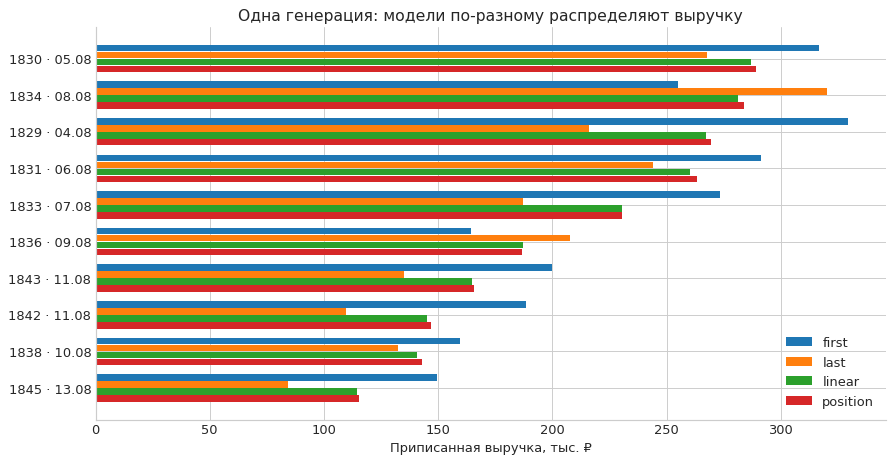

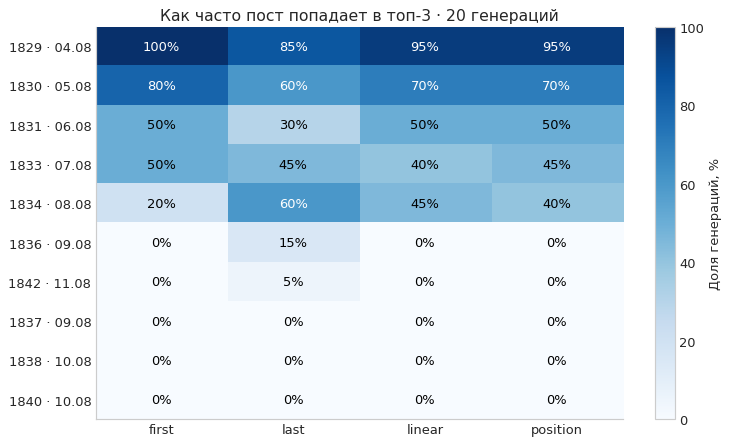

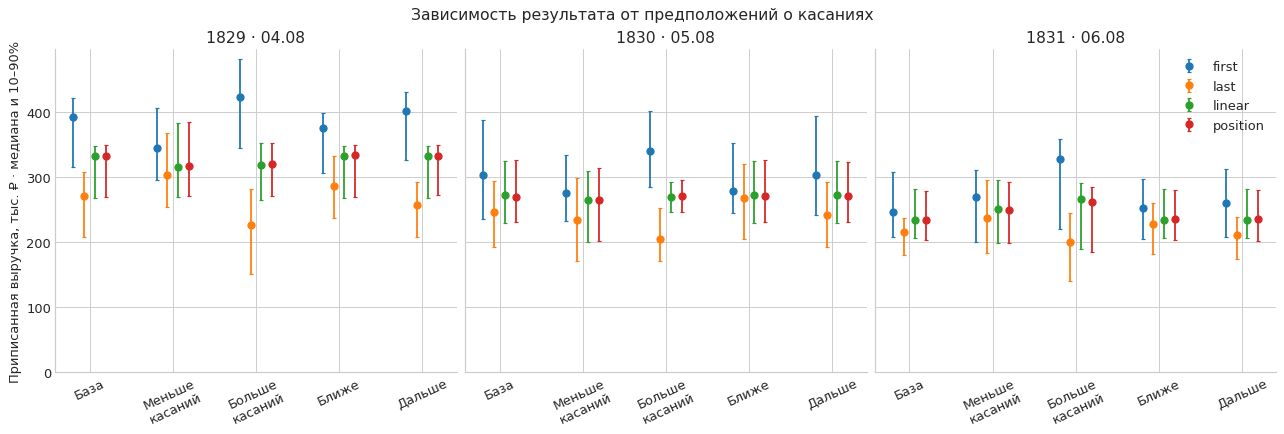

,config,model,most_frequent_post,frequency
0,Базовое,first,history_post_1829,1.00
1,Базовое,last,history_post_1829,0.85
2,Базовое,linear,history_post_1829,0.95
3,Базовое,position,history_post_1829,0.95
4,Меньше касаний,first,history_post_1829,0.90
5,Меньше касаний,last,history_post_1829,0.95
6,Меньше касаний,linear,history_post_1829,0.90
7,Меньше касаний,position,history_post_1829,0.90
8,Больше касаний,first,history_post_1829,1.00
9,Больше касаний,last,history_post_1834,0.85


In [4]:
def label(pid):
    row=placements.loc[pid]
    return f"{int(row.post_id)} · {row.publication_time:%d.%m}"
selected=base_revenue.mean(axis=1).nlargest(10).index
fig,ax=plt.subplots(figsize=(12,6))
for k,model in enumerate(MODELS):
    ax.barh(np.arange(len(selected))+(k-1.5)*.19,base_revenue.loc[selected,model]/1000,height=.18,label=model)
ax.set_yticks(np.arange(len(selected)),[label(p) for p in selected]);ax.invert_yaxis()
ax.set(xlabel='Приписанная выручка, тыс. ₽',title='Одна генерация: модели по-разному распределяют выручку')
ax.legend();save(fig,'01_models_revenue')
base_freq=frequency[frequency.config.eq('Базовое')].pivot(index='placement_id',columns='model',values='top3_frequency').reindex(columns=MODELS)
selected_freq=base_freq.mean(axis=1).nlargest(10).index
fig,ax=plt.subplots(figsize=(10,6))
mat=base_freq.loc[selected_freq]*100
im=ax.imshow(mat,vmin=0,vmax=100,cmap='Blues',aspect='auto')
for i in range(len(mat)):
    for j in range(4):ax.text(j,i,f'{mat.iloc[i,j]:.0f}%',ha='center',va='center',color='white' if mat.iloc[i,j]>55 else 'black')
ax.set_yticks(range(len(mat)),[label(p) for p in mat.index]);ax.set_xticks(range(4),MODELS)
ax.set_title(f'Как часто пост попадает в топ-{TOP_K} · {len(SEEDS)} генераций')
ax.grid(False);fig.colorbar(im,ax=ax,label='Доля генераций, %');save(fig,'02_top3_stability')
# Полный разброс доли выручки выбранных публикаций при разных предположениях.
chosen=base_freq.mean(axis=1).nlargest(3).index
fig,axes=plt.subplots(1,3,figsize=(15,5),sharey=True,layout='constrained')
for ax,pid in zip(axes,chosen):
    for j,model in enumerate(MODELS):
        vals=[];low=[];high=[]
        for config in CONFIGS:
            x=runs.loc[runs.placement_id.eq(pid)&runs.model.eq(model)&runs.config.eq(config),'revenue']/1000
            q=x.quantile([.1,.5,.9]);vals.append(q.loc[.5]);low.append(q.loc[.5]-q.loc[.1]);high.append(q.loc[.9]-q.loc[.5])
        ax.errorbar(np.arange(len(CONFIGS))+(j-1.5)*.13,vals,yerr=[low,high],fmt='o',capsize=2,label=model)
    ax.set_xticks(range(5),['База','Меньше\nкасаний','Больше\nкасаний','Ближе','Дальше'],rotation=25)
    ax.set_title(label(pid));ax.set_ylim(bottom=0)
axes[0].set_ylabel('Приписанная выручка, тыс. ₽ · медиана и 10–90%')
axes[-1].legend();fig.suptitle('Зависимость результата от предположений о касаниях')
save(fig,'03_assumptions')
# Читаемые результаты и происхождение, без оценок причинного эффекта.
summary=[]
for config in CONFIGS:
    for model in MODELS:
        f=frequency[frequency.config.eq(config)&frequency.model.eq(model)].sort_values(['top3_frequency','placement_id'],ascending=[False,True]).iloc[0]
        summary.append(dict(config=config,model=model,most_frequent_post=f.placement_id,frequency=f.top3_frequency))
summary=pd.DataFrame(summary)
display(summary)
summary.to_csv(OUTPUT/'summary.csv',index=False)
manifest={'experiment_only':True,'contract_version':'1.3','seeds':SEEDS,'base_seed':BASE_SEED,'window_days':WINDOW_DAYS,'top_k':TOP_K,'configs':CONFIGS,'manual_checks_passed':len(checks),'generator_sha256':hashlib.sha256(source_path.read_bytes()).hexdigest(),'engine_sha256':hashlib.sha256((ROOT/'src/core/attribution.py').read_bytes()).hexdigest(),'source_sha256':{p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ['metrics.md','data/raw/base.csv','data/processed/analysis_posts_v2.csv']},'as_of':pd.Timestamp.now(tz='UTC').isoformat()}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print('Общая выручка:',base['orders'].amount.sum())
print('Без касаний:',no_touch.iloc[0])
print('Топ-3 seed42:',{m:base_revenue[m].nlargest(TOP_K).index.tolist() for m in MODELS})


## Как читать выводы

Успешные ручные примеры и инварианты подтверждают работу расчёта на проверенных случаях, но не полноту тестирования платформы. Не проверены Telegram-интерфейс, доступ, хранение, интеграция, комиссия и ROMI. Неоднозначные одновременные разные заказы требуют отдельного правила.

Совпадение рейтингов означает согласие правил на выбранных путях, а не правильность причинного вывода. Ранние посты имеют больше возможностей попасть в пути: генератор равномерно выбирает среди опубликованных постов, доступных до покупки. Поэтому устойчивое преимущество ранних публикаций может отражать конструкцию генератора. Задержка касания меняет временной порядок, но не вводит предпочтение категории или соответствие курсу.

20 повторов на предположение дают предварительную оценку устойчивости (частоты меняются шагом 5 процентных пунктов). Внешний спрос и эффект рекламы не разделены. Модель для реальной работы нельзя объявить наиболее точной по этим результатам. Следующий шаг — наблюдать реальные касания и проверять рекламные решения рандомизированным экспериментом.


## Результат выполненного запуска

- 16 ручных случаев × 4 модели = **64 успешные проверки**.
- 5 предположений × 20 генераций × 4 модели = **400 расчётов** с проверками сохранения выручки каждого заказа и допустимости касаний.
- На базовой выборке общая выручка 5 904 671,67 ₽; без сгенерированных касаний осталось 1 862 158,33 ₽. Эта сумма сохранена во всех четырёх моделях и не названа доказанной органикой.
- При seed=42 лидируют разные посты: first — 1829, last — 1834, linear и position — 1830.
- В 20 базовых генерациях пост 1829 входит в топ-3 в 100% случаев у first, 85% у last и 95% у linear/position. Это ранний пост от 4 августа: генератор даёт ранним публикациям больше возможностей попасть в пути. Частота не доказывает рекламный эффект.
- Пост 1834 — сторонняя магистратура, однако он лидирует у last на базовой выборке. Генератор выбирает посты без соответствия купленному продукту. Это ограничение предположений, а не подтверждение эффективности сторонней рекламы.
- Изменение числа касаний заметно меняет распределение между first и last; linear и position на этих коротких путях дают близкие результаты. Это не означает их причинную точность.

**Готово:** проверка функции расчёта и предварительная оценка чувствительности. **Не установлено:** лучшая модель по реальной эффективности, эффект внешних событий, инкрементальная выручка и готовность всей платформы к запуску. Для этого нужны реальные касания и отдельная проверка интеграции/эксперимента.
